# **Machine Learning Project**
<span style="font-size: 23px;">**Prediction price of used car**</span><br><br>
ML-проект по решению задачи предсказания цены использованного автомобиля на основе сопутствующих признаков.

В качестве данных используется датасет с **[Kaggle](https://www.kaggle.com/)**: **[Used Car Price Prediction Dataset](https://www.kaggle.com/datasets/taeefnajib/used-car-price-prediction-dataset/data)**. Целевой переменной считается `price` (цена автомобиля).

## Гипотезы

**Г1:** Между пробегом автомобиля и его ценой (признаки `milage` и `price` соответственно) существует отрицательная корреляция.

**Проверка:** Построить диаграмму рассеяния для двух признаков и посмотреть на получившийся график с линией тренда.
<br>
<br>    
**Г2:** Наличие чистого ПТС (признак `clean_title`) влияет на цену автомобиля, есть положительная корреляция.

**Проверка:** Закодировать признак на этапе разведочного анализа и проанализировать тепловую карту.
<br>
<br>
<br>
**Г3:** Показатель $R^2$ будет лучше, если заменить год производства автомобиля на его возраст. Возможно, начало отсчёта с 0 позволит модели улучшить показатели точности, в отличие от работы с годичной временной шкалой.

**Проверка:** Построить два пайплайна, один будет содержать столбцы с возрастом, другой - с годом производства. Сравнить критерий $R^2$ в двух случаях.
<br>
<br>
<br>
**Г4:** Логарифмирование таргета улучшит метрику $R^2$ моделей.

**Проверка:** Построить два пайплайна: один без логарифмирования таргета, другой - с логарифмированием (с использованием `TransformedTargetRegressor`) и оценить $R^2$.
<br>
<br>
<br>
**Г5:** Нахождение лучших параметров с использованием GridSearchCV даст прирост в метрике $R^2$ по сравнению с базовыми настройками моделей.

**Проверка:** Обучение модели на стандартных настройках, затем подбор параметров. Сравнение метрик моделей.

## Импорт необходимых библиотек

In [197]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from datetime import datetime

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.compose import TransformedTargetRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectKBest, f_regression

Запишем датасет в переменную `df` и посмотрим на количество строк и столбцов:

In [198]:
df = pd.read_csv('/kaggle/input/datasets/taeefnajib/used-car-price-prediction-dataset/used_cars.csv')
df.shape

(4009, 12)

Посмотрим на структуру датасета и типы данных:

In [199]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [200]:
df.dtypes

brand           object
model           object
model_year       int64
milage          object
fuel_type       object
engine          object
transmission    object
ext_col         object
int_col         object
accident        object
clean_title     object
price           object
dtype: object

In [201]:
X = df.drop(columns='price')
y = df['price'].str.replace(r'[^\d.]', '', regex=True).astype(float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=52)

df_t = X_train.copy()
df_t['price'] = y_train

## EDA (Разведочный анализ данных)

Проведем анализ обучающей выборки датасета, посмотрим на структуру, типы данных, признаки.

In [202]:
df_t.isna().sum()

brand             0
model             0
model_year        0
milage            0
fuel_type       137
engine            0
transmission      0
ext_col           0
int_col           0
accident         95
clean_title     484
price             0
dtype: int64

### Распределения числовых величин

Рассмотрим распределения числовых величин и построим boxplot'ы для их оценки.
После применения `dtypes` можно заметить, что большинство столбцов - это тип *object*, значит сейчас нужно корректно обработать числовые признаки. Можно использовать регулярное выражение для получения числа из колонки `price`:

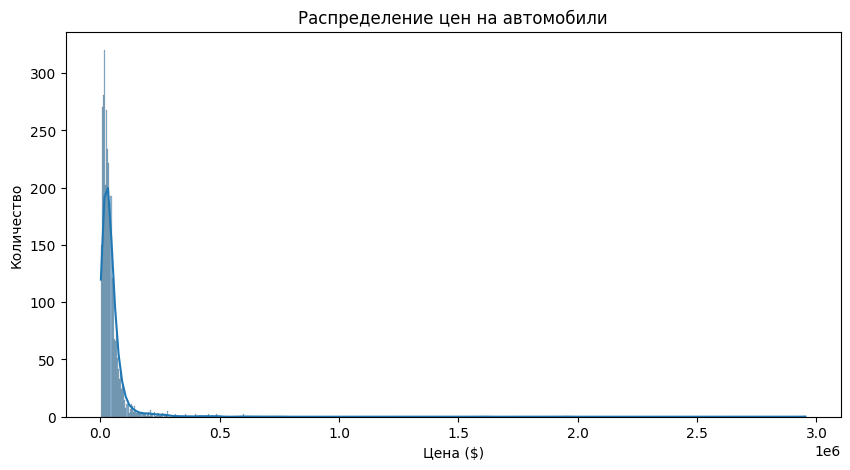

In [203]:
plt.figure(figsize=(10, 5))
sns.histplot(df_t['price'], bins='auto', kde=True)
plt.title('Распределение цен на автомобили')
plt.xlabel('Цена ($)')
plt.ylabel('Количество')
plt.show()

Можно заметить "длинный хвост" у данного распределения. Попробуем провести анализ по логарифмической шкале: 

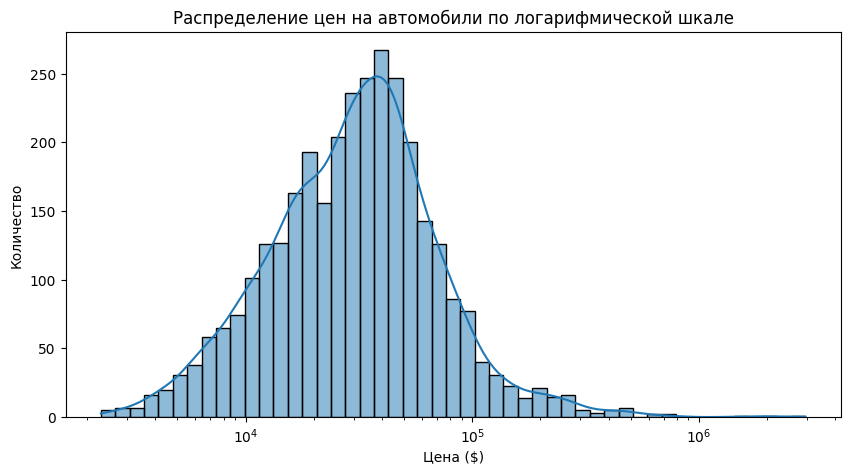

In [204]:
plt.figure(figsize=(10,5))
sns.histplot(df_t['price'], bins='auto', kde=True, log_scale=True)
plt.title('Распределение цен на автомобили по логарифмической шкале')
plt.xlabel('Цена ($)')
plt.ylabel('Количество')
plt.show()

Рассмотрим также распределения для величины пробега и года выпуска авто:

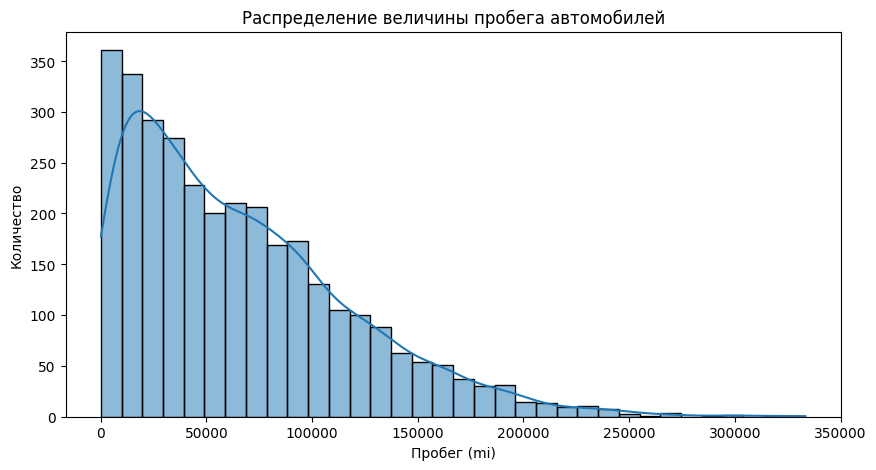

In [205]:
modern_milage = df_t['milage'].astype(str).str.replace(r'[^\d]', '', regex=True)
df_t['milage'] = pd.to_numeric(modern_milage, errors='coerce')

plt.figure(figsize=(10,5))
sns.histplot(df_t['milage'], bins='auto', kde=True)
plt.xlabel('Пробег (mi)')
plt.ylabel('Количество')
plt.title('Распределение величины пробега автомобилей')
plt.show()

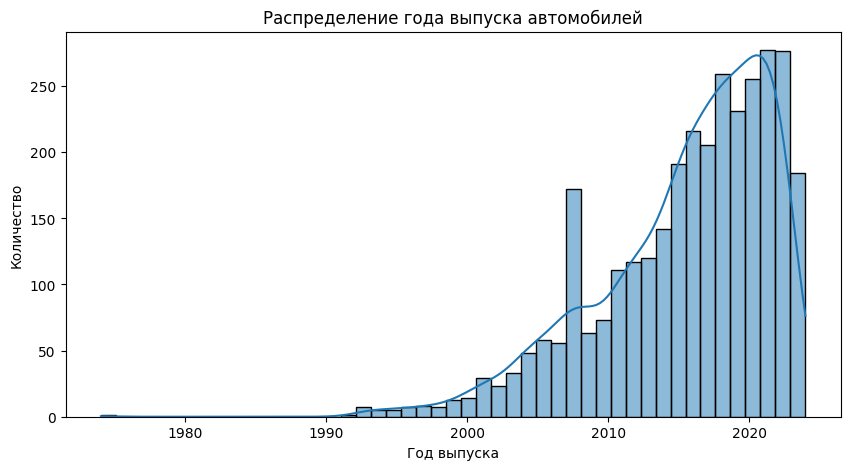

In [206]:
plt.figure(figsize=(10,5))
sns.histplot(df_t['model_year'], bins='auto', kde=True)
plt.title('Распределение года выпуска автомобилей')
plt.xlabel('Год выпуска')
plt.ylabel('Количество')
plt.show()

Распределение величин пробега и года выпуска имеют смещения влево и вправо соответственно. Вероятно, дело в выбросах. Проверим числовые характеристики на минимальные и максимальные значения.

In [207]:
df_t[['milage', 'model_year', 'price']].describe().style.format("{:.2f}")

,milage,model_year,price
count,3207.00,3207.00,3207.00
mean,65583.04,2015.47,45225.67
std,52545.82,6.10,84973.94
min,100.00,1974.00,2300.00
25%,23146.50,2012.00,17000.00
50%,54000.00,2017.00,31000.00
75%,95475.00,2020.00,49995.00
max,333361.00,2024.00,2954083.00


### Диаграммы рассеяния

Изобразим две диаграммы рассеяния для цены и пробега, а также для года выпуска и пробега. Добавим также линию тренда в оба графика.

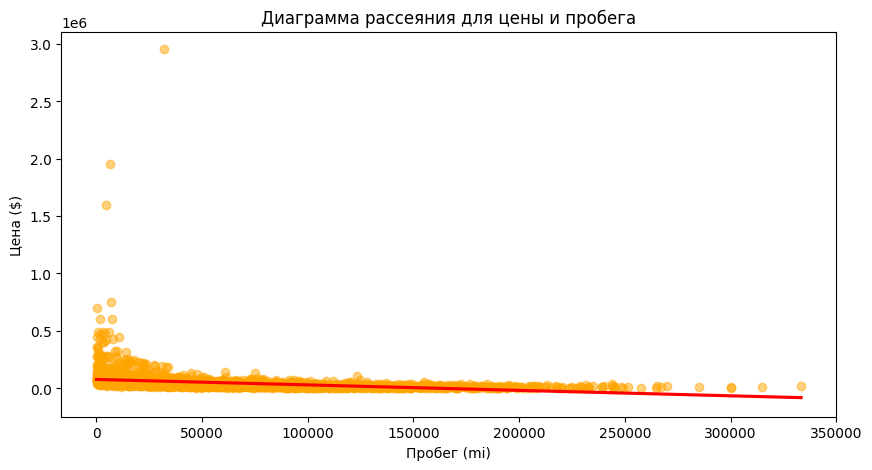

In [208]:
plt.figure(figsize=(10,5))
sns.regplot(data=df_t, x='milage', y='price', color='red', scatter_kws={'alpha': 0.5, 'color': 'orange'})
plt.title('Диаграмма рассеяния для цены и пробега')
plt.xlabel('Пробег (mi)')
plt.ylabel('Цена ($)')
plt.show()

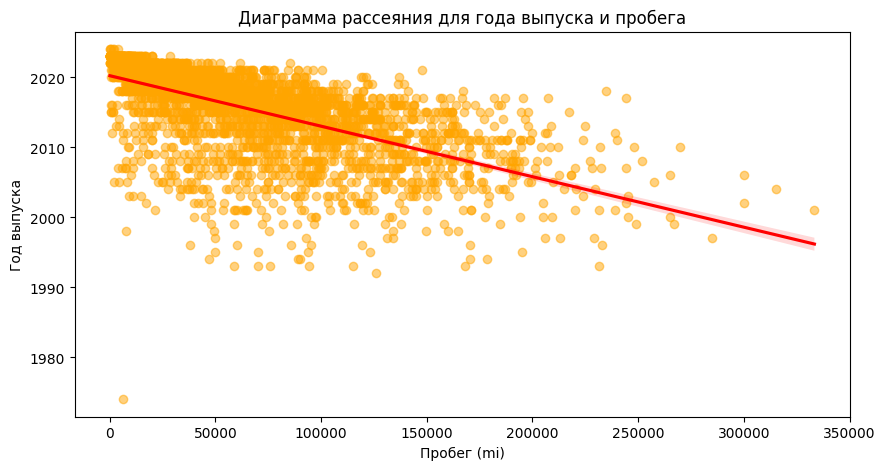

In [209]:
plt.figure(figsize=(10,5))
sns.regplot(data=df_t, x='milage', y='model_year', color='red', scatter_kws={'alpha': 0.5, 'color': 'orange'})
plt.title('Диаграмма рассеяния для года выпуска и пробега')
plt.xlabel('Пробег (mi)')
plt.ylabel('Год выпуска')
plt.show()

С графиком пробега/года производства всё ясно, есть отрицательная корреляция, ведь мы рассматриваем автомобили, которыми пользовались, а значит величина пробега постепенно возрастала.<br><br>
С диаграммой рассеяния для пробега и цены всё сложнее: прямая похожа на горизонтальную. Возможно, дело в выбросах.

### Диаграммы размаха

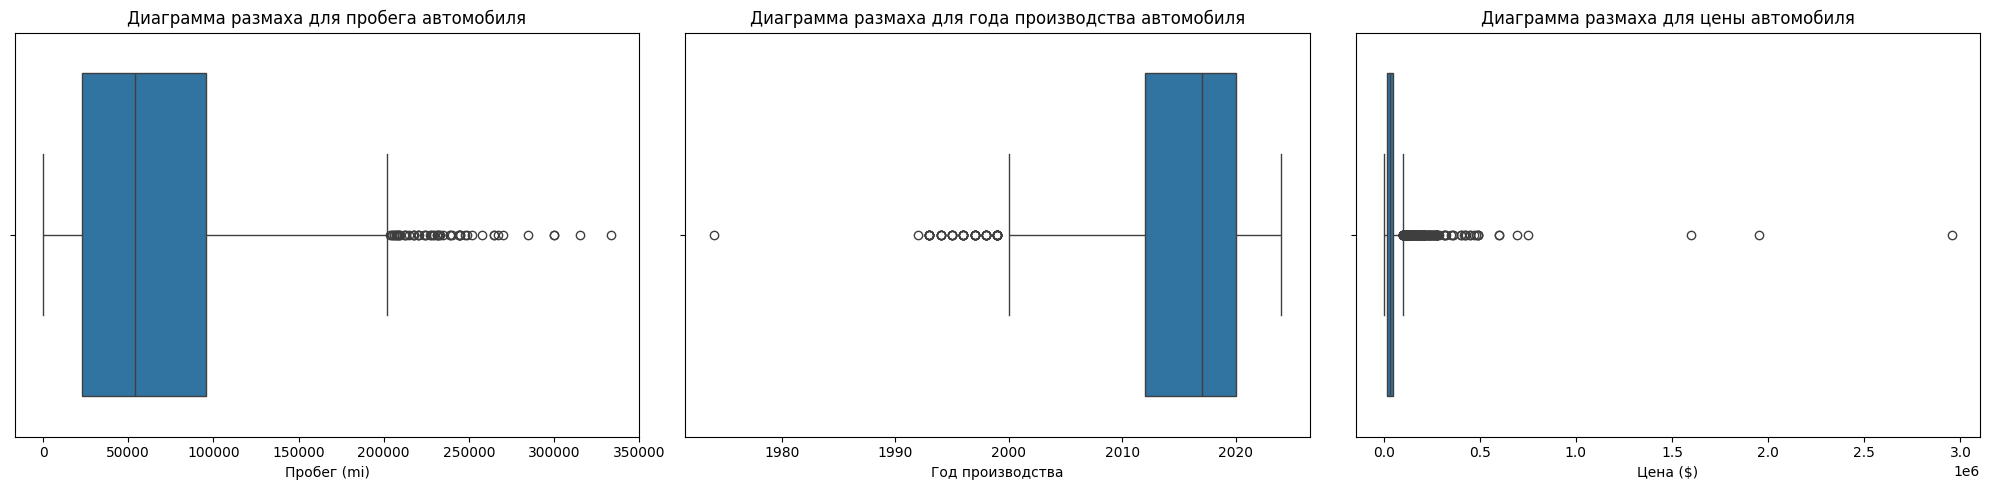

In [210]:
fig, axes = plt.subplots(1, 3, figsize=(20,5))
sns.boxplot(ax=axes[0], x=df_t['milage'])

axes[0].set_title('Диаграмма размаха для пробега автомобиля')
axes[0].set_xlabel('Пробег (mi)')

sns.boxplot(ax=axes[1], x=df_t['model_year'])
axes[1].set_title('Диаграмма размаха для года производства автомобиля')
axes[1].set_xlabel('Год производства')

sns.boxplot(ax=axes[2], x=df_t['price'])
axes[2].set_title('Диаграмма размаха для цены автомобиля')
axes[2].set_xlabel('Цена ($)')

plt.tight_layout()

Действительно, точки, которые слишком сильно выделяются на фоне остальных данных являются выбросами. Посмотрим на самые большие цены и величины пробега, а также на минимальные годы выпуска:

In [211]:
df_t[df_t['price'] > 1000000][['brand', 'model', 'model_year', 'milage', 'clean_title', 'price']]

,brand,model,model_year,milage,clean_title,price
693,Maserati,Quattroporte Base,2005,32000,Yes,2954083.0
3046,Porsche,Carrera GT Base,2005,4400,Yes,1599000.0
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330,Yes,1950995.0


In [212]:
old_cars = df_t[df_t['model_year'] < 2000][['brand', 'model', 'model_year', 'milage', 'clean_title', 'price']]
print(f'Кол-во строк в этой таблице = {len(old_cars)}\nСнизу лишь часть данных:')
old_cars.head(15)

Кол-во строк в этой таблице = 54
Снизу лишь часть данных:


,brand,model,model_year,milage,clean_title,price
1465,Porsche,Boxster Base,1999,72000,Yes,12250.0
2983,Jeep,Wrangler Sport,1997,131000,Yes,5500.0
2867,Lexus,SC 300 Base,1998,165000,Yes,8700.0
626,Pontiac,Firebird Base,1999,158000,Yes,2500.0
685,GMC,Suburban 2500,1996,95000,Yes,25000.0
692,Honda,Civic EX,1993,58981,Yes,9599.0
3663,Pontiac,Firebird Trans Am,1997,134033,Yes,7200.0
1328,BMW,328 i,1997,206000,Yes,15900.0
167,Lexus,LX 470 Base,1999,82000,Yes,25000.0
1355,Toyota,Land Cruiser Base,1996,233000,Yes,7500.0


In [213]:
df_t[df_t['milage'] > 250000][['brand', 'model', 'model_year', 'milage', 'clean_title', 'price']] 

,brand,model,model_year,milage,clean_title,price
499,Toyota,Highlander Hybrid Limited,2006,264893,Yes,5000.0
2558,Toyota,Land Cruiser Base,2010,269885,Yes,22500.0
2485,Dodge,Challenger SRT8,2008,251634,Yes,10500.0
3118,Dodge,Dakota Sport,1997,285000,Yes,6399.0
618,Volvo,S40 T5,2005,257700,Yes,3550.0
3158,Toyota,4Runner 4WD,1999,267000,Yes,8000.0
2175,Ford,Excursion Limited,2001,333361,Yes,17000.0
1145,GMC,Sierra 3500 SLE,2002,300000,Yes,5000.0
3757,Ford,F-250 XL Crew Cab Super Duty,2004,315000,Yes,9200.0
31,Dodge,Ram 1500 Laramie Mega Cab,2006,300183,Yes,10900.0


С очень высоким показателем цены выделяются авто с чистым ПТС и малым пробегом: Bugatti, Maserati, Porsche.

Изобразим тот же график рассеяния, только с более чистыми данными:

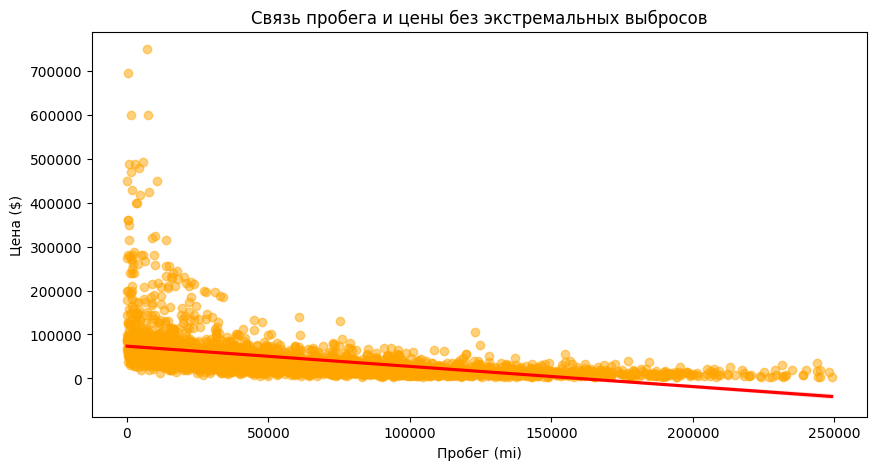

In [214]:
plt.figure(figsize=(10,5))
outlier_mask = (df_t['milage'] < 250000) & (df_t['price'] < 1000000)
sns.regplot(data=df_t[outlier_mask], x='milage', y='price', color='red', scatter_kws={'alpha': 0.5, 'color': 'orange'})
plt.xlabel('Пробег (mi)')
plt.ylabel('Цена ($)')
plt.title('Связь пробега и цены без экстремальных выбросов')
plt.show()

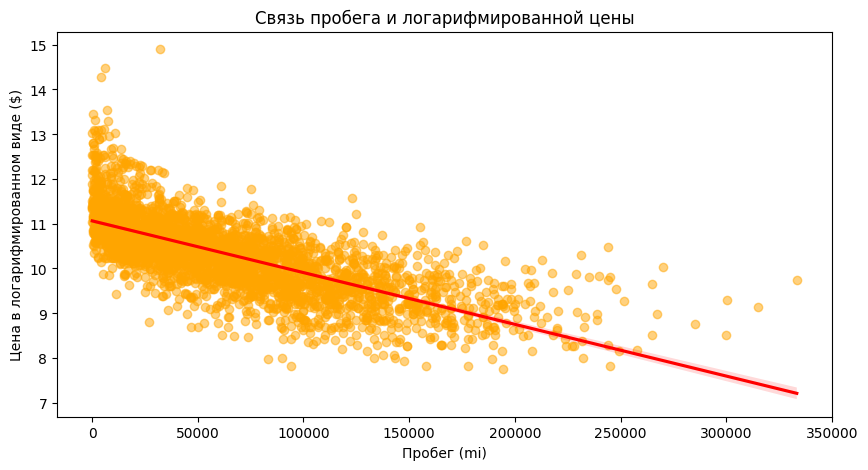

In [215]:
df_t['log_prices'] = np.log1p(df_t['price'])

plt.figure(figsize=(10,5))
sns.regplot(data=df_t, x='milage', y='log_prices', color='red', scatter_kws={'alpha': 0.5, 'color': 'orange'})
plt.title('Связь пробега и логарифмированной цены')
plt.xlabel('Пробег (mi)')
plt.ylabel('Цена в логарифмированном виде ($)')
plt.show()

df_t = df_t.drop(columns='log_prices')

При логарифмировании цены прослеживается более сильный наклон линии тренда, на график сверху (который без логарифмирования) действует некоторое количество выбросов, которые поднимают правую часть прямой, из-за этого она больше похожа на горизонтальную, однако всё равно зависимость присутствует, **гипотеза №1 об отрицательной корреляции цены и пробега подтвердилась**.

### Анализ уникальных значений признаков
Посмотрим на остальные признаки. Проанализируем уникальные значения в каждом из них.

In [216]:
for column in df_t.columns:
    print(f'Столбец {column}', end='\n\n')
    print(df_t[column].unique(), f'\nКоличество уникальных значений = {len(df_t[column].unique())}', sep='\n')
    print('------------------------------------------------------------------------------')

Столбец brand

['Jeep' 'Ford' 'Subaru' 'GMC' 'Audi' 'Porsche' 'RAM' 'BMW' 'Toyota'
 'Rolls-Royce' 'Nissan' 'Land' 'Chevrolet' 'Dodge' 'Chrysler' 'Cadillac'
 'Mercedes-Benz' 'INFINITI' 'Lexus' 'Lamborghini' 'Mazda' 'Acura' 'Rivian'
 'Volkswagen' 'Honda' 'Hyundai' 'Saturn' 'Genesis' 'Kia' 'Bentley' 'Buick'
 'MINI' 'Hummer' 'Tesla' 'Jaguar' 'Maserati' 'Aston' 'Mercury'
 'Mitsubishi' 'Pontiac' 'Lincoln' 'FIAT' 'Scion' 'Alfa' 'Ferrari'
 'McLaren' 'Lotus' 'Volvo' 'Polestar' 'Karma' 'smart' 'Suzuki' 'Saab'
 'Maybach' 'Bugatti' 'Lucid']

Количество уникальных значений = 56
------------------------------------------------------------------------------
Столбец model

['Wagoneer Series II 4x4' 'Expedition Max Limited' 'Outback 2.5i Premium'
 ... 'Maverick XL' 'ProMaster 2500 Window Van High Roof'
 'Pacifica Launch Edition']

Количество уникальных значений = 1674
------------------------------------------------------------------------------
Столбец model_year

[2022 2021 2013 2017 2008 2016 2011 2

Какие-то признаки можно убрать. Они могут запутать модель из-за количества уникальных значений и отсутствия полезной информации.<br>
* Убираем `int_col` и `ext_col`. Цвета интерьера и кузова не дадут нам нужной пользы, их очень много, и цвет на б/у авто влияет минимально.

Что ещё можно заметить:
* `log_prices` убираем, рассмотрим поведение на логарифмической шкале позже.
* `clean_title` будем кодировать как 0 и 1 для *NaN* и *Yes* соответственно.
* `accident` тоже можно закодировать, но нужно учитывать пропущенные данные.

### Кодирование бинарных признаков и устранение пропусков

In [217]:
acc_col = len(df_t['accident'])
acc_nan = df_t['accident'].isna().sum()
acc_false = len(df_t[df_t['accident'] == 'None reported'])
acc_true = acc_col - acc_nan - acc_false
print(f'Количество значений: {acc_col}\nКоличество NaN: {acc_nan}\nКоличество авто без ДТП: {acc_false} \nКоличество авто с ДТП: {acc_true}')

Количество значений: 3207
Количество NaN: 95
Количество авто без ДТП: 2313 
Количество авто с ДТП: 799


Пропуски у `accident` можно заполнить модой. Так как признаков немало, и есть вероятность удалить важные данные, то смысла сносить такие объекты нет.

Пропуски у `clean_title` заполняем просто как No.

### Извлечение значений л.с. и объёмов двигателей

Попробуем теперь поработать с `engine`. Можно извлечь с помощью регулярного выражения данные о лошадиных силах и литраже двигателя и добавить 2 новые колонки.


In [219]:
df_t['horsepower'] = df_t['engine'].str.extract(r'(\d+\.?\d*)\s*HP').astype(float) # Берём числа, после которых идёт 'HP', числа с точкой тоже
df_t['engine_volume'] = df_t['engine'].str.extract(r'(\d+\.?\d*)\s*(?:L|Liter)').astype(float) # Здесь тоже берём числа, после которых идёт 'L' или 'Liter'

In [220]:
df_t.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,horsepower,engine_volume
422,Jeep,Wagoneer Series II 4x4,2022,29800,Gasoline,"HEMI 5.7L V-8 variable valve control, regular ...","Automatic, 8-Spd",–,–,None reported,NaN,58900.0,NaN,5.7
3295,Ford,Expedition Max Limited,2021,30918,Gasoline,375.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,10-Speed A/T,White,Beige,None reported,Yes,51999.0,375.0,3.5
2819,Subaru,Outback 2.5i Premium,2013,116000,Gasoline,173.0HP 2.5L 4 Cylinder Engine Gasoline Fuel,A/T,Blue,Beige,At least 1 accident or damage reported,Yes,12500.0,173.0,2.5
3690,GMC,Yukon XL Denali,2017,124000,Gasoline,420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel,8-Speed A/T,Gray,Beige,At least 1 accident or damage reported,Yes,32000.0,420.0,6.2
1396,Audi,Q7 Premium Plus,2022,22588,Hybrid,3.0 Liter TFSI,Automatic,Navarra Blue,Saiga Beige,None reported,NaN,52598.0,NaN,3.0


In [221]:
print(f'Количество пропусков у лош. сил: {df_t['horsepower'].isna().sum()} из {len(df_t)}\nКоличество пропусков у объёма двигателя: {df_t['engine_volume'].isna().sum()} из {len(df_t)}')

Количество пропусков у лош. сил: 659 из 3207
Количество пропусков у объёма двигателя: 170 из 3207


Попробуем заполнить пропуски в л.с., сгруппировав значения по каждому бренду авто. 

То есть мы берём медиану лошадиных сил у каждого бренда по отдельности и заполняем ей пропуски у авто соответствующих марок.

Если в выборке обнаружим какой-то новый бренд и пропущенное значение л.с., то заполняем средним по брендам.

### Кодирование бинарных признаков

Построим матрицу корреляций и изобразим тепловую карту на основе временного датасета `df_eda`. Закодируем бинарные категориальные признаки с помощью `get_dummies`:

In [222]:
df_t['clean_title'] = df_t['clean_title'].fillna('No') #df_t - это копия X_train
df_eda = pd.get_dummies(df_t, columns=['accident', 'clean_title'], drop_first=True)
display(df_eda.head())

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,price,horsepower,engine_volume,accident_None reported,clean_title_Yes
422,Jeep,Wagoneer Series II 4x4,2022,29800,Gasoline,"HEMI 5.7L V-8 variable valve control, regular ...","Automatic, 8-Spd",–,–,58900.0,NaN,5.7,True,False
3295,Ford,Expedition Max Limited,2021,30918,Gasoline,375.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,10-Speed A/T,White,Beige,51999.0,375.0,3.5,True,True
2819,Subaru,Outback 2.5i Premium,2013,116000,Gasoline,173.0HP 2.5L 4 Cylinder Engine Gasoline Fuel,A/T,Blue,Beige,12500.0,173.0,2.5,False,True
3690,GMC,Yukon XL Denali,2017,124000,Gasoline,420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel,8-Speed A/T,Gray,Beige,32000.0,420.0,6.2,False,True
1396,Audi,Q7 Premium Plus,2022,22588,Hybrid,3.0 Liter TFSI,Automatic,Navarra Blue,Saiga Beige,52598.0,NaN,3.0,True,False


Мы временно заполнили пропуски у `clean_title`, в дальнейшем будем работать с `X_train`.

`df_t` нужен был для просмотра закономерностей и анализа, ничего в X мы ещё не записывали и ничего не заполняли.

### Матрица корреляций и тепловая карта

Матрицу будем строить на основе числовых и двух бинарных признаков, уберём лишние данные из временного датасета и **изобразим тепловую карту**: 

In [223]:
df_eda = df_eda.drop(columns=['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col'])

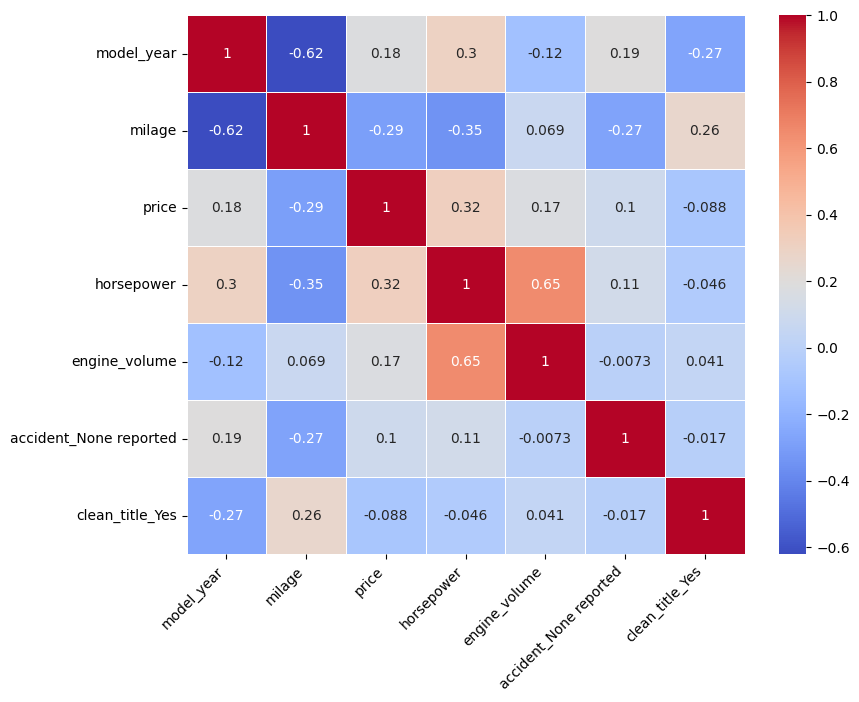

In [224]:
corr_matrix = df_eda.corr()
plt.figure(figsize=(9,7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.xticks(rotation=45, ha='right')
plt.show()

По тепловой карте можно заметить, что у цены и чистого ПТС вообще отрицательная корреляция, хоть и по модулю небольшая. Значит, **гипотеза №2** о положительной корреляции чистого ПТС и цены **не подтвердилась**.

## Подготовка данных

Создадим кастомный трансформер для извлечения показателей лошадиных сил и объёма двигателя и создания новых признаков. Также л.с. будем группировать по брендам и заполнять по медиане. Если остаются пропуски, то берём среднее среди всех брендов. У `clean_title` заполним пропуск как No, так как там либо NaN, либо Yes, это особенность признака датасета.

Также учтём модификацию с возрастом автомобиля, это нужно для проверки гипотезы о влиянии возраста на метрику.

In [225]:
class CarFeaturesTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, use_age=False, reference_year=2026):
        self.use_age = use_age
        self.reference_year = reference_year

    def fit(self, X, y=None):
        X = X.copy()

        horsepower = X['engine'].str.extract(r'(\d+\.?\d*)\s*HP', expand=False).astype(float)
        engine_volume = X['engine'].str.extract(r'(\d+\.?\d*)\s*(?:L|Liter)', expand=False).astype(float)
        
        self.engine_volume_median_ = engine_volume.median()

        temp_df = pd.DataFrame({
            'brand': X['brand'],
            'horsepower': horsepower
        })

        self.horsepower_by_brand_ = temp_df.groupby('brand')['horsepower'].median()

        self.residual_median_ = self.horsepower_by_brand_.mean()

        return self


    def transform(self, X):
        X = X.copy()

        X['horsepower'] = X['engine'].str.extract(r'(\d+\.?\d*)\s*HP', expand=False).astype(float)
        X['engine_volume'] = X['engine'].str.extract(r'(\d+\.?\d*)\s*(?:L|Liter)', expand=False).astype(float)

        modern_milage = X['milage'].astype(str).str.replace(r'[^\d]', '', regex=True)
        X['milage'] = pd.to_numeric(modern_milage, errors='coerce')

        X['horsepower'] = (X['horsepower'].fillna(X['brand'].map(self.horsepower_by_brand_)).fillna(self.residual_median_))
        
        X['engine_volume'] = X['engine_volume'].fillna(self.engine_volume_median_)

        X['clean_title'] = X['clean_title'].fillna('No')

        if self.use_age:
            X['age'] = self.reference_year - X['model_year']
            X = X.drop(columns=['model_year'])

        X = X.drop(columns=['engine', 'int_col', 'ext_col'])
        
        return X

Выбираем категориальные и скалярные признаки, используем `RobustScaler()`, чтобы лучше справляться с выбросами.

In [226]:
num_features_year = ['model_year', 'milage', 'horsepower', 'engine_volume']
num_features_age = ['age', 'milage', 'horsepower', 'engine_volume']
cat_features = ['brand', 'fuel_type', 'accident', 'clean_title', 'model', 'transmission']

input_sc_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

input_enc_cat = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor_year = ColumnTransformer([
    ('num', input_sc_num, num_features_year),
    ('cat', input_enc_cat, cat_features)
])

preprocessor_age = ColumnTransformer([
    ('num', input_sc_num, num_features_age),
    ('cat', input_enc_cat, cat_features)
])

## Обучение моделей

Используем 4 модели, пока изучим показатель R2, посмотрим на влияние возраста автомобиля, а также как работают модели с логарифмированным таргетом.

In [227]:
models = [LinearRegression(), Lasso(), Ridge(), DecisionTreeRegressor(random_state=52)]

results = []

for model in models:
    pipeline_year = Pipeline([
        ('features', CarFeaturesTransformer()),
        ('prep', preprocessor_year),
        ('model', model)
    ])
    
    pipeline_age = Pipeline([
        ('features', CarFeaturesTransformer(use_age=True)),
        ('prep', preprocessor_age),
        ('model', model)
    ])
    
    score_year = cross_val_score(pipeline_year, X_train, y_train, cv=5, scoring='r2').mean()
    score_age = cross_val_score(pipeline_age, X_train, y_train, cv=5, scoring='r2').mean()

    results.append((score_year, score_age))

r2_y = [score[0] for score in results]
r2_a = [score[1] for score in results]

output = pd.DataFrame({
    'Model': ['Linear Regression', 'Lasso', 'Ridge', 'Decision Tree'],
    'R2 score w/year': r2_y,
    'R2 score w/age': r2_a 
})
    
output.style.hide()

Model,R2 score w/year,R2 score w/age
Linear Regression,0.355774,0.355774
Lasso,0.384240,0.384240
Ridge,0.420128,0.420128
Decision Tree,0.431495,0.410802


Использование возраста не дало серьёзного прироста модели решающего дерева, а для Ridge, Lasso и Linear Regression вообще не оказало никакого влияния. Возможно, это из-за линейности операции, а модель дерева и линейные отработали немного по-разному из-за их подхода к решению этой задачи. **Гипотеза №3 о влиянии возраста автомобиля на метрику не подтвердилась**. Оставляем `model_year` для дальнейшей работы.

### Логарифмирование таргета

Теперь прологарифмируем таргет:

In [228]:
common_prep = Pipeline([
    ('features', CarFeaturesTransformer()),
    ('prep', preprocessor_year)
])

results = []

for model in models:
    pipeline_log = Pipeline([
        ('common_prep', common_prep),
        ('model', TransformedTargetRegressor(regressor=model,
                                             func=np.log1p,
                                             inverse_func=np.expm1)
        )
    ])

    score_log_target = cross_val_score(pipeline_log, X_train, y_train, cv=5, scoring='r2').mean()
    
    results.append(score_log_target)


output = pd.DataFrame({
    'Model w/log target': ['Linear Regression', 'Lasso', 'Ridge', 'Decision Tree'],
    'R2 score': results
})

output.style.hide()

Model w/log target,R2 score
Linear Regression,0.072094
Lasso,-0.047611
Ridge,0.522219
Decision Tree,0.368878


Логарифмирование таргета улучшило показатели лишь у Ridge-регрессии, у других моделей всё хуже. Вероятно, обычная лин. регрессия без регуляризации не справляется с некоторыми авто, из-за чего веса могли получить большой модуль, у Lasso стандартный параметр регуляризации мог просто сильно штрафовать маленький таргет (лог. в масштабе другой, нежели обычный таргет). А дереву решений не нужен лог. таргет, это нелинейный алгоритм, здесь изменение шкалы лишь мешает. **Гипотеза №4 о положительном влиянии логарифмирования таргета подтвердилась частично**.

## Подбор гиперпараметров с GridSearchCV
Подберем гиперпараметры с использованием `GridSearchCV`:

In [229]:
gs_pipeline = Pipeline([
    ('common_prep', common_prep),
    ('model', TransformedTargetRegressor(func=np.log1p, inverse_func=np.expm1))
])

param_grids = {
    'Ridge': {
        'model__regressor': [Ridge()],
        'model__regressor__alpha': np.logspace(-3, 3, 20) # От 0.001 до 1000
    },

    'Lasso': {
        'model__regressor': [Lasso(max_iter=3000)],
        'model__regressor__alpha': np.logspace(-5, 1, 20) # От 0.00001 до 10
    },

    'Decision Tree': {
        'model__regressor': [DecisionTreeRegressor(random_state=52)],
        'model__regressor__max_depth': [3, 5, 7, 10, 15],
        'model__regressor__min_samples_leaf': [1, 2, 5, 10, 20],
        'model__regressor__min_samples_split': [2, 5, 10, 20]
    }
}

best_models = []

for model, p_grid in param_grids.items():
    grid = GridSearchCV(estimator=gs_pipeline, param_grid=p_grid, cv=5, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)

    best_models.append({
        'Model': model,
        'Best R2 score': grid.best_score_,
        'Best Params': grid.best_params_
    })

output = pd.DataFrame(best_models)

Определим функцию для удобного вывода параметров:

In [230]:
output = pd.DataFrame(best_models)
def format_params(params):
    cleaned = []
    for k, v in params.items():
        if k in ('model', 'model__regressor'):
            continue

        param_name = k.replace('model__regressor__', '').replace('model__', '')
        
        if isinstance(v, (float, np.floating)):
            val_str = f"{v:.2e}" if (0 < abs(v) < 0.001) else f"{v:.4f}"
        else:
            val_str = str(v)
        cleaned.append(f"{param_name}={val_str}")

    return ", ".join(cleaned)

output['Best Params'] = output['Best Params'].apply(format_params)

(output.style
    .format({'Best R2 score': '{:.4f}'})
    .set_properties(**{'text-align': 'left'})
    .hide())

Model,Best R2 score,Best Params
Ridge,0.5231,alpha=1.4384
Lasso,0.4994,alpha=3.79e-04
Decision Tree,0.4036,"max_depth=15, min_samples_leaf=10, min_samples_split=2"


Без логарифмирования таргета:

In [231]:
gs_pipeline_no_log = Pipeline([
    ('common_prep', common_prep),
    ('model', 'passthrough')
])

param_grids = {
    'Ridge': {
        'model': [Ridge()],
        'model__alpha': np.logspace(-3, 3, 20) # От 0.001 до 1000
    },

    'Decision Tree': {
        'model': [DecisionTreeRegressor(random_state=52)],
        'model__max_depth': [3, 5, 7, 10, 15],
        'model__min_samples_leaf': [1, 2, 5, 10, 20],
        'model__min_samples_split': [2, 5, 10, 20]
    }
}

best_models_no_log = []

for model, p_grid in param_grids.items():
    grid = GridSearchCV(estimator=gs_pipeline_no_log, param_grid=p_grid, cv=5, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)

    best_models_no_log.append({
        'Model w/o log target': model,
        'Best R2 score': grid.best_score_,
        'Best Params': grid.best_params_
    })

output = pd.DataFrame(best_models_no_log)

output['Best Params'] = output['Best Params'].apply(format_params)

output.style.format({'Best R2 score': '{:.4f}'}).set_properties(**{'text-align': 'left'}).hide()

Model w/o log target,Best R2 score,Best Params
Ridge,0.4215,alpha=1.4384
Decision Tree,0.4437,"max_depth=15, min_samples_leaf=1, min_samples_split=2"


Действительно, `GridSearchCV` подобрал оптимальные параметры для улучшения всех моделей. При условии двух проверок - с логарифмированием и без, всё равно на всех моделях показатель R2 стал выше. **Гипотеза №5 об улучшении показателей при использовании `GridSearchCV` подтвердилась**.

## Отбор признаков

Рассмотрим выбор признаков на основе `SelectKBest`. Лучшим показателем был 0.52 у Ridge, эту модель и используем:

In [232]:
from sklearn.feature_selection import SelectKBest, f_regression
pipeline_selection = Pipeline([
    ('common_prep', common_prep),
    ('selection', SelectKBest(score_func=f_regression, k=100)),
    ('model', TransformedTargetRegressor(
        regressor=Ridge(alpha=1.4384),
        func=np.log1p,
        inverse_func=np.expm1
    ))
])

param_grid = {
    'selection__k': [50, 100, 200, 500, 1000, 'all']
}

gs_ridge_k = GridSearchCV(estimator=pipeline_selection, param_grid=param_grid, cv=5, scoring='r2', n_jobs=-1)

gs_ridge_k.fit(X_train, y_train)

output = pd.DataFrame({
    'Best R2 score': gs_ridge_k.best_score_,
    'Best K': gs_ridge_k.best_params_
})

output.style.format({'Best R2 score': '{:.4f}'}).hide()

Best R2 score,Best K
0.5231,all


Лучше брать все признаки, так показатель коэффициента детерминации будет выше.

## Итоговый тест

Теперь проведём финальный тест и добавим ещё 2 метрики - MAE и RMSE.

In [233]:
y_test_pred = gs_ridge_k.best_estimator_.predict(X_test)

r2 = r2_score(y_test, y_test_pred)
mae = mean_absolute_error(y_test, y_test_pred)
rmse = mean_squared_error(y_test, y_test_pred)**0.5

output = pd.DataFrame({
    'R2': [r2],
    'Mean absolute error (MAE)': [mae],
    'Root of mean squared error (RMSE)': [rmse]
})
output.style.format({
    'Mean absolute error (MAE)': '{:.4f}',
    'Root of mean squared error (RMSE)': '{:.4f}',
    'R2': '{:.4f}'
}).hide()

R2,Mean absolute error (MAE),Root of mean squared error (RMSE)
0.7722,8250.6299,21808.7171



У таргета (цены) есть изменчивость, а его оценка происходит на основе признаков автомобилей. 
Коэффициент детерминации `R2 = 0.77` на итоговом тесте говорит о доле этой изменчивости, которую модель смогла объяснить. Причём R2 заметно выше на тестовой выборке. Вероятно, выбросы и особенные модели попали в тренировочные данные и создавали шум, из-за чего коэффициент падал. В тестовой данные могли распределиться так, что серьезных отвлекающих факторов нет. В теории даже random_state мог оказать влияние на такое разбиение. Стоит также учитывать, что в тренировочных данных мы видели серьёзные выбросы, даже посмотрели на эти автомобили (Bugatti, Porsche, ...). Может, в тестовой их не было.

Средняя абсолютная ошибка со значением `MAE = 8250.6` выражается в тех же единицах, что и цена ($) и показывает среднее число, на которое отклоняется предсказание от идеального.
<br><br>
Корень из среднеквадратической ошибки `RMSE = 21808.7`тоже выражается в тех же единицах, только явно показывает, как модель ошибается на выбросах или экстремальных значениях цен. Этот показатель превышает среднюю абсолютную ошибку в несколько раз, значит модель всё же испытывает сложности с прогнозированием цен особенных авто.